# Laboratorium: Adaline i spadek gradientu

**Podstawy AI**

Na poprzednich zajęciach perceptron uczył się na pomyłkach: błąd $y - \hat y$ miał tylko wartości $0, \pm 1$. Dziś zbudujesz **Adaline** (Widrow i Hoff, 1960): neuron, który wie, *jak bardzo* się myli, i uczy się, minimalizując **funkcję straty** metodą **spadku gradientu**.

Plan:
1. spadek gradientu na jednej wadze (kartka 1 w kodzie),
2. implementacja Adaline,
3. Adaline na danych Iris: za duże i za małe $\eta$, granica stabilności,
4. mapa $\eta$ × epoki: kiedy więcej epok pomaga,
5. granica decyzyjna w czasie: co się dzieje, gdy trafność jest już 100%.

Dziś skupiamy się na zrozumieniu, jak $\eta$ i liczba epok wpływają na uczenie. Standaryzację i stochastyczny spadek gradientu poznamy na następnych zajęciach.

**Jak pracujemy:** komórki oznaczone `# TODO` uzupełniasz sam. W eksperymentach stosujemy zasadę **przewiduję → uruchamiam → wyjaśniam**.

**Na koniec:** wrzuć uzupełniony notebook na swojego GitHuba.

Notebook wzoruje się na rozdziale 2 książki S. Raschki *Machine Learning with PyTorch and Scikit-Learn*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris

np.set_printoptions(precision=4, suppress=True)

## 1. Spadek gradientu na jednej wadze

Na kartce 1 liczyłeś ręcznie kroki spadku gradientu dla

$$L(w) = (w - 3)^2, \qquad w_{k+1} = w_k - \eta \cdot 2(w_k - 3), \qquad w_0 = 0.$$

Teraz to samo w kodzie, dla wielu kroków i wielu wartości $\eta$.

### Zadanie 1
Uzupełnij funkcję `spadek_1d`: w pętli policz kolejne $w_{k+1}$ z $w_k$ i dopisz do listy. Funkcja zwraca listę $[w_0, w_1, \dots, w_n]$.

In [2]:
def spadek_1d(eta, w0=0.0, n_krokow=10):
    w = w0
    trajektoria = [w]
    for k in range(n_krokow):
        # Jeden krok spadku gradientu dla L(w) = (w - 3)^2
        w = w - eta * 2 * (w - 3)
        trajektoria.append(w)
    return trajektoria

In [3]:
# Sprawdzenie z kartką 1: pierwsze trzy kroki
for eta in [0.25, 1.0, 1.1]:
    print(f"η = {eta:<5}", [round(w, 4) for w in spadek_1d(eta, n_krokow=3)])

η = 0.25  [0.0, 1.5, 2.25, 2.625]
η = 1.0   [0.0, 6.0, 0.0, 6.0]
η = 1.1   [0.0, 6.6, -1.32, 8.184]


Powinieneś zobaczyć dokładnie to, co na kartce: $[0, 1.5, 2.25, 2.625]$, $[0, 6, 0, 6]$ i $[0, 6.6, -1.32, 8.184]$.

Teraz narysujmy trajektorie dla większej liczby $\eta$, po 10 kroków.

**Przewiduję:** przy którym $\eta$ z listy $\{0.1,\ 0.25,\ 0.5,\ 0.9,\ 1.0,\ 1.1\}$ dojdziemy do minimum najszybciej?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** ...

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for eta in [0.1, 0.25, 0.5, 0.9, 1.0, 1.1]:
    ax.plot(range(11), spadek_1d(eta), marker="o", label=f"η = {eta}")
ax.axhline(3, color="k", ls=":", label="minimum w = 3")
ax.set_xlabel("krok k"); ax.set_ylabel("$w_k$"); ax.set_ylim(-6, 12)
ax.legend(ncol=2); plt.show()

for eta in [0.1, 0.25, 0.5, 0.9, 1.0, 1.1]:
    print(f"η = {eta:<4}  w_10 = {spadek_1d(eta)[-1]:10.4f}")

**Pytanie 1.** (a) Przy którym $\eta$ dochodzimy do minimum w **jednym** kroku? (b) Dlaczego przy $\eta = 0.9$ waga skacze na boki, a mimo to zbiega? (c) Gdzie jest granica między zbieżnością a rozbieżnością?

Wskazówka: przekształć wzór na krok do postaci $w_{k+1} - 3 = c \cdot (w_k - 3)$. Ile wynosi $c$?

✍️ **Twoja odpowiedź:** (a) Do minimum w jednym kroku dochodzimy przy $\eta = 0.5$ (wtedy $w_1 = 0 - 0.5 \cdot 2(0 - 3) = 3$).
(b) Przy $\eta = 0.9$ waga skacze na boki, ponieważ współczynnik $1 - 2\eta = 1 - 1.8 = -0.8$ jest ujemny (powoduje oscylacje ze zmianą znaku), ale ponieważ jego wartość bezwzględna $\vert{}-0.8\vert{} < 1$, błędy maleją co krok, co prowadzi do zbieżności.   
(c) Granica między zbieżnością a rozbieżnością leży przy $\eta = 1$ (dla $\eta > 1$ oscylacje narastają i proces się rozbiega).

## 2. Adaline — przypomnienie

Neuron liczy, tak jak perceptron, **pobudzenie** $z = \mathbf{w}^T\mathbf{x} + b$. Różnica jest w uczeniu:

| | perceptron | Adaline |
|---|---|---|
| błąd | $y - \hat{y}$, tylko $0, \pm 1$ | $y - z$, dowolna liczba |
| poprawka | po każdym przykładzie | raz na epokę, z całego zbioru |
| predykcja | $\hat y = 1$, gdy $z \ge 0$ | $\hat y = 1$, gdy $z \ge 0.5$ |

**Funkcja straty** (średni błąd kwadratowy, MSE) mówi jedną liczbą, jak źle jest:

$$L(\mathbf{w}, b) = \frac{1}{n}\sum_{i=1}^{n}\left(y^{(i)} - z^{(i)}\right)^2$$

**Spadek gradientu.** Pochodne straty po wagach i biasie (wyprowadzenie na slajdach):

$$\frac{\partial L}{\partial w_j} = -\frac{2}{n}\sum_i \left(y^{(i)} - z^{(i)}\right) x_j^{(i)}, \qquad \frac{\partial L}{\partial b} = -\frac{2}{n}\sum_i \left(y^{(i)} - z^{(i)}\right)$$

Robimy krok w stronę przeciwną do gradientu:

$$w_j := w_j + \eta \cdot \frac{2}{n}\sum_i \left(y^{(i)} - z^{(i)}\right) x_j^{(i)}, \qquad b := b + \eta \cdot \frac{2}{n}\sum_i \left(y^{(i)} - z^{(i)}\right)$$

### Zadanie 2 — uzupełnij metodę `fit`

Brakuje **czterech linijek** w pętli uczącej:
1. `errors` — wektor błędów $y - z$ dla **wszystkich** przykładów naraz (`output` jest już policzone),
2. aktualizacja wag `self.w_`,
3. aktualizacja biasu `self.b_`,
4. `loss` — średni błąd kwadratowy w tej epoce.

Wskazówki:
- sumę $\sum_i e^{(i)} x_j^{(i)}$ dla wszystkich $j$ naraz liczy `X.T @ errors`,
- $n$ to `X.shape[0]`,
- średnią liczy `.mean()`, kwadrat `** 2`.

Parametr `verbose=True` wypisuje stan po każdej epoce, tak jak liczyłeś na kartce.

In [4]:
class AdalineGD:
    """ADAptive LInear NEuron, uczony pełnym spadkiem gradientu (etykiety 0/1).

    Parametry
    ---------
    eta : float        współczynnik uczenia
    n_iter : int       liczba epok
    w_init : str       'random' (małe losowe, jak u Raschki) albo 'zeros'
    random_state : int ziarno generatora liczb losowych
    verbose : bool     czy wypisywać stan po każdej epoce

    Atrybuty po uczeniu
    -------------------
    w_ : wagi,  b_ : bias,  losses_ : wartość MSE w każdej epoce
    """

    def __init__(self, eta=0.01, n_iter=50, w_init="random", random_state=1, verbose=False):
        self.eta = eta
        self.n_iter = n_iter
        self.w_init = w_init
        self.random_state = random_state
        self.verbose = verbose

    def fit(self, X, y):
        if self.w_init == "zeros":
            self.w_ = np.zeros(X.shape[1])
        else:
            rgen = np.random.RandomState(self.random_state)
            self.w_ = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1])
        self.b_ = 0.0
        self.losses_ = []

        for epoka in range(1, self.n_iter + 1):
            net_input = self.net_input(X)          # z dla WSZYSTKICH przykładów naraz
            output = self.activation(net_input)    # Adaline: aktywacja liniowa, output = z

            errors = y - output                    # 1. wektor błędów y − z
            self.w_ += self.eta * 2.0 * X.T @ errors / X.shape[0]  # 2. aktualizacja wag (η · 2/n · X.T @ errors)
            self.b_ += self.eta * 2.0 * errors.mean()              # 3. aktualizacja biasu (η · 2 · średnia błędów)
            loss = (errors ** 2).mean()            # 4. średni błąd kwadratowy (MSE)

            self.losses_.append(loss)
            if self.verbose:
                print(f"epoka {epoka}: z = {output}, błędy = {errors}, "
                      f"MSE = {loss:.4f} -> nowe w = {self.w_}, b = {self.b_:.4f}")
        return self

    def net_input(self, X):
        """Pobudzenie z = w^T x + b"""
        return np.dot(X, self.w_) + self.b_

    def activation(self, X):
        """Liniowa funkcja aktywacji: sigma(z) = z"""
        return X

    def predict(self, X):
        """Klasa po progu 0.5"""
        return np.where(self.activation(self.net_input(X)) >= 0.5, 1, 0)

## 3. Sprawdzenie na przykładzie z kartki 2

Punkty A–D z poprzednich zajęć, start od zerowych wag, $\eta = 0.05$, dwie epoki. Na kartce 2 liczyłeś:
- epoka 1: $z = 0$ dla wszystkich, błędy $(1, 0, 1, 0)$, MSE $= 0.5$, nowe wagi $w = (0.125,\ 0.075)$, $b = 0.05$,
- epoka 2: $z = (0.375,\ 0.4,\ 0.575,\ 0.2)$, MSE $\approx 0.193$.

In [5]:
X_kartka = np.array([[2, 1], [1, 3], [3, 2], [0, 2]], dtype=float)
y_kartka = np.array([1, 0, 1, 0])

ada_k = AdalineGD(eta=0.05, n_iter=2, w_init="zeros", verbose=True).fit(X_kartka, y_kartka)

epoka 1: z = [0. 0. 0. 0.], błędy = [1. 0. 1. 0.], MSE = 0.5000 -> nowe w = [0.125 0.075], b = 0.0500
epoka 2: z = [0.375 0.4   0.575 0.2  ], błędy = [ 0.625 -0.4    0.425 -0.2  ], MSE = 0.1928 -> nowe w = [0.1781 0.0719], b = 0.0612


In [6]:
# Test: jeśli ta komórka nie zgłasza błędu, Twoja implementacja jest poprawna
ada_1 = AdalineGD(eta=0.05, n_iter=1, w_init="zeros").fit(X_kartka, y_kartka)
assert np.allclose(ada_1.w_, [0.125, 0.075]) and np.isclose(ada_1.b_, 0.05), f"Po 1. epoce: w={ada_1.w_}, b={ada_1.b_}"
assert np.allclose(ada_k.losses_, [0.5, 0.1928125]), f"Straty: {ada_k.losses_}"
print("✅ Wynik zgodny z kartką")
print("predykcje po 1. epoce:", ada_1.predict(X_kartka), " prawdziwe:", y_kartka)

✅ Wynik zgodny z kartką
predykcje po 1. epoce: [0 0 1 0]  prawdziwe: [1 0 1 0]


**Pytanie 2.** Po pierwszej epoce punkt B jest klasyfikowany poprawnie ($z = 0.4 < 0.5$), a mimo to w drugiej epoce wnosi do poprawki błąd $-0.4$. Perceptron w takiej sytuacji nie zmieniłby wag z powodu B. Dlaczego Adaline to robi i co na tym zyskuje?

✍️ **Twoja odpowiedź:** Adaline dąży do tego, aby wartość $z$ była jak najbliżej etykiety (0 lub 1), a nie tylko po „właściwej stronie” progu (0.5). Nawet jeśli punkt jest już sklasyfikowany poprawnie, ale jego $z$ nie jest idealne (np. $z = 0.4$), Adaline koryguje wagi, aby zwiększyć margines pewności i poprawić dopasowanie liniowe.

**Pytanie 3.** Raschka pokazuje też wersję aktualizacji wag z pętlą po wagach:
```python
for j in range(self.w_.shape[0]):
    self.w_[j] += self.eta * (2.0 * (X[:, j] * errors)).mean()
```
Dlaczego to daje ten sam wynik co `self.eta * 2.0 * X.T @ errors / X.shape[0]`? Co oblicza wiersz `j` macierzy `X.T` pomnożony przez `errors`?

✍️ **Twoja odpowiedź:**  Pętla po wagach mnoży wektor cechy $j$ przez błędy dla wszystkich przykładów i wylicza średnią, co matematycznie jest dokładnie tym samym, co iloczyn macierzowy X.T @ errors podzielony przez liczbę wierszy $n$.

## 4. Iris: za duże i za małe $\eta$

Te same dane co tydzień temu: setosa (0) i versicolor (1), długość działki i długość płatka, w centymetrach.

In [7]:
iris = load_iris()
X = iris.data[:100][:, [0, 2]]               # cechy: działka, płatek [cm]
y = (iris.target[:100] == 1).astype(int)      # setosa -> 0, versicolor -> 1
print("Kształt X:", X.shape, " Liczba przykładów w klasach:", np.bincount(y))

Kształt X: (100, 2)  Liczba przykładów w klasach: [50 50]


In [9]:
def plot_decision_regions(X, y, model, resolution=0.02, ax=None, title=None, etykiety=("setosa", "versicolor")):
    ax = ax or plt.gca()
    cmap = ListedColormap(["tab:red", "tab:blue"])
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))
    Z = model.predict(np.array([xx1.ravel(), xx2.ravel()]).T).reshape(xx1.shape)
    ax.contourf(xx1, xx2, Z, alpha=0.25, cmap=cmap)
    for klasa, kolor, marker in [(0, "tab:red", "o"), (1, "tab:blue", "s")]:
        ax.scatter(X[y == klasa, 0], X[y == klasa, 1], c=kolor, marker=marker,
                   edgecolor="black", label=etykiety[klasa])
    ax.set_xlim(x1_min, x1_max); ax.set_ylim(x2_min, x2_max)
    if title: ax.set_title(title)
    ax.legend(loc="upper left")

### Eksperyment A: $\eta = 0.1$ i $\eta = 0.0001$

Uczymy Adaline przez 15 epok z dwoma współczynnikami uczenia.

**Przewiduję:** jak będzie wyglądał wykres straty w obu przypadkach? (Przypomnij sobie kartkę 1.)

Dla $\eta = 0.1$: Strata będzie gwałtownie rosnąć (wykres wystrzeli w górę do potężnych wartości rzędu $10^{20}$), ponieważ wartość $\eta$ jest za duża, przekracza granicę stabilności i algorytm rozbiega się, przeskakując minimum.   
Dla $\eta = 0.0001$: Strata będzie maleć bardzo powoli i niemal liniowo, ale w minimalnym stopniu, ponieważ współczynnik uczenia jest zbyt mały, by cofnąć błąd w zaledwie 15 epokach.

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** ...

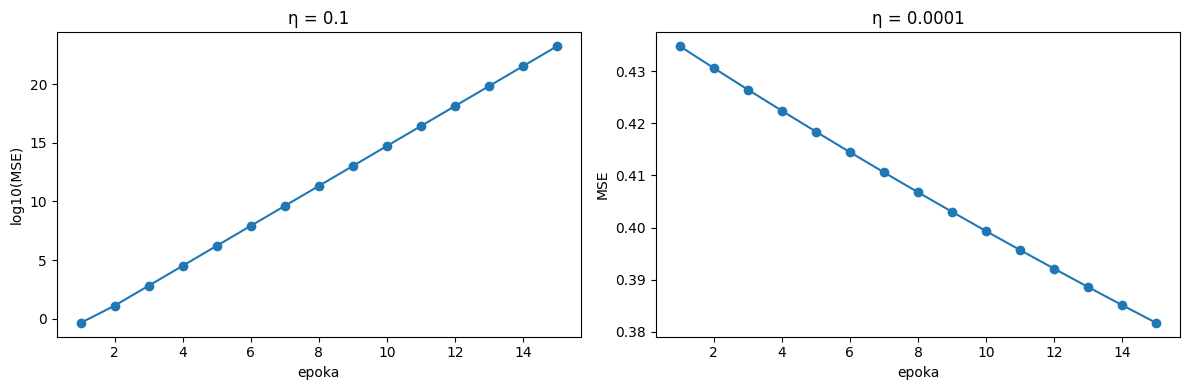

η = 0.1:    MSE w epokach 1, 2, 3: [  0.43  12.99 648.81]  ... w 15.: 1.7e+23
η = 0.0001: MSE w 1. i 15. epoce:  0.435 0.382
trafność:  η = 0.1: 0.5   η = 0.0001: 0.5


In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ada1 = AdalineGD(eta=0.1, n_iter=15).fit(X, y)
axs[0].plot(range(1, 16), np.log10(ada1.losses_), marker="o")
axs[0].set_xlabel("epoka"); axs[0].set_ylabel("log10(MSE)"); axs[0].set_title("η = 0.1")

ada2 = AdalineGD(eta=0.0001, n_iter=15).fit(X, y)
axs[1].plot(range(1, 16), ada2.losses_, marker="o")
axs[1].set_xlabel("epoka"); axs[1].set_ylabel("MSE"); axs[1].set_title("η = 0.0001")

plt.tight_layout(); plt.show()
print("η = 0.1:    MSE w epokach 1, 2, 3:", np.round(ada1.losses_[:3], 2), " ... w 15.:", f"{ada1.losses_[-1]:.1e}")
print("η = 0.0001: MSE w 1. i 15. epoce: ", round(ada2.losses_[0], 3), round(ada2.losses_[-1], 3))
print("trafność:  η = 0.1:", (ada1.predict(X) == y).mean(), "  η = 0.0001:", (ada2.predict(X) == y).mean())

Uwaga: lewy wykres ma oś pionową w skali logarytmicznej ($\log_{10}$). Wartość 20 oznacza stratę rzędu $10^{20}$.

**Pytanie 4.** Co się stało w obu przypadkach? Który przypadek z kartki 1 ($\eta = 0.25$, $1$, $1.1$) przypomina każdy z wykresów? Dlaczego oba modele mają trafność tylko 50%?

✍️ **Twoja odpowiedź:** Przy $\eta = 0.1$ (lewy wykres): Współczynnik uczenia jest zbyt duży dla tego wielowymiarowego zbioru danych. Algorytm przekracza minimum w każdym kroku, a strata gwałtownie rośnie (eksploduje numerycznie), osiągając po 15 epokach gigantyczne wartości rzędu $10^{23}$ (w skali logarytmicznej $\log_{10}$).

Przy $\eta = 0.0001$ (prawy wykres): Współczynnik uczenia jest drastycznie za mały. Strata maleje, ale niezwykle powolnie (zaledwie z ok. $0.435$ do $0.382$ w ciągu 15 epok), ponieważ kroki spadku gradientu są mikroskopijne.


Przypadek $\eta = 0.1$ na Iris przypomina zachowanie z kartki dla $\eta = 1.1$ (w obu dochodzi do rozbieżności, z tą różnicą, że w 1D waga oscylowała i uciekała na zewnątrz, a w wielowymiarowym Iris błąd rośnie wykładniczo).

Przypadek $\eta = 0.0001$ na Iris przypomina powolne, niemrawe zbliżanie się do minimum, co w uproszczeniu nawiedza sytuację zbyt małego kroku (choć na kartce najmniejszym $\eta$ było $0.25$, które tam akurat zbiegało szybko, ale analogią dla braku postępu jest skrajnie zachowawczy krok).

Dla $\eta = 0.1$: Wagi uległy całkowitemu „zepsuciu” (przepełnieniu numerycznym/NaN), przez co model generuje bezsensowne predykcje (zgaduje losowo z 50-procentową skutecznością).

Dla $\eta = 0.0001$: W ciągu zaledwie 15 epok wagi prawie w ogóle nie zdążyły się zmienić względem losowego punktu startowego – prosta decyzyjna nie zdążyła się przesunąć i rozdzielić klas, więc model poprawnie klasyfikuje tylko połowę obiektów (czysty los).


### Zadanie 3: granica stabilności

Ucz Adaline przez **100 epok** dla $\eta \in \{0.001,\ 0.01,\ 0.02,\ 0.022,\ 0.024,\ 0.025,\ 0.026,\ 0.03\}$. Dla każdego $\eta$ wypisz MSE w pierwszej i ostatniej epoce oraz trafność. Znajdź największe $\eta$, przy którym strata jeszcze **maleje**.

(Przy dużych $\eta$ liczby mogą wyjść poza zakres `float` i NumPy wypisze ostrzeżenie o przepełnieniu — linijka `np.errstate` je wycisza.)

In [11]:
with np.errstate(over="ignore", invalid="ignore"):
    for eta in [0.001, 0.01, 0.02, 0.022, 0.024, 0.025, 0.026, 0.03]:
        ada = AdalineGD(eta=eta, n_iter=100).fit(X, y)
        trafnost = (ada.predict(X) == y).mean()
        print(f"η = {eta:<6} | MSE 1. epoka: {ada.losses_[0]:.4f} | MSE 100. epoka: {ada.losses_[-1]:10.4g} | trafność: {trafnost:.0%}")

η = 0.001  | MSE 1. epoka: 0.4348 | MSE 100. epoka:     0.1202 | trafność: 100%
η = 0.01   | MSE 1. epoka: 0.4348 | MSE 100. epoka:    0.01443 | trafność: 100%
η = 0.02   | MSE 1. epoka: 0.4348 | MSE 100. epoka:    0.01243 | trafność: 100%
η = 0.022  | MSE 1. epoka: 0.4348 | MSE 100. epoka:    0.01242 | trafność: 100%
η = 0.024  | MSE 1. epoka: 0.4348 | MSE 100. epoka:    0.01241 | trafność: 100%
η = 0.025  | MSE 1. epoka: 0.4348 | MSE 100. epoka:      32.36 | trafność: 50%
η = 0.026  | MSE 1. epoka: 0.4348 | MSE 100. epoka:  1.124e+08 | trafność: 50%
η = 0.03   | MSE 1. epoka: 0.4348 | MSE 100. epoka:  1.399e+30 | trafność: 50%


**Pytanie 5.** Gdzie leży granica stabilności dla tych danych? Porównaj z granicą $\eta < 1$ z punktu 1. Dlaczego tutaj jest dużo mniejsza?

✍️ **Twoja odpowiedź:** Granica stabilności dla tych danych wynosi ok. $\eta \approx 0.024$ – $0.025$. Jest ona znacznie mniejsza niż $\eta < 1$ z przypadku 1D, ponieważ w wielowymiarowej przestrzeni maksymalny bezpieczny krok zależy od skali cech w macierzy danych ($X^T X / n$). Cechy w Iris mają wartości rzędu 1–7 cm, co mocno skaluje pochodną gradientu.

## 5. Mapa $\eta$ × epoki

Czy za małe $\eta$ da się nadrobić większą liczbą epok? A za duże?

### Zadanie 4
Dla $\eta \in \{0.001,\ 0.005,\ 0.01,\ 0.02,\ 0.025\}$ i liczby epok $\in \{15,\ 100,\ 1000\}$ naucz Adaline i zapisz MSE w ostatniej epoce oraz trafność. Wypisz wyniki jako tabelę: wiersze to $\eta$, kolumny to liczba epok.

**Przewiduję:** czy $\eta = 0.001$ po 1000 epokach dogoni $\eta = 0.01$ po 100 epokach?

✍️ **Moje przewidywanie (zapisz przed uruchomieniem):** tak

In [12]:
etas = [0.001, 0.005, 0.01, 0.02, 0.025]
epoki = [15, 100, 1000]

print("η        " + "".join(f"{n:>22} epok" for n in epoki))
with np.errstate(over="ignore", invalid="ignore"):
    for eta in etas:
        wiersz = f"{eta:<8} "
        for n in epoki:
            # TODO: naucz AdalineGD(eta=eta, n_iter=n) i dopisz do wiersza MSE i trafność,
            #       np. wiersz += f"{mse:>14.3g} / {traf:.0%}"
            pass
        print(wiersz)

η                            15 epok                   100 epok                  1000 epok
0.001    
0.005    
0.01     
0.02     
0.025    


Zobaczmy to samo na wykresie: krzywe strat dla wszystkich $\eta$ przez 1000 epok (oś pozioma w skali logarytmicznej, żeby było widać i początek, i koniec).

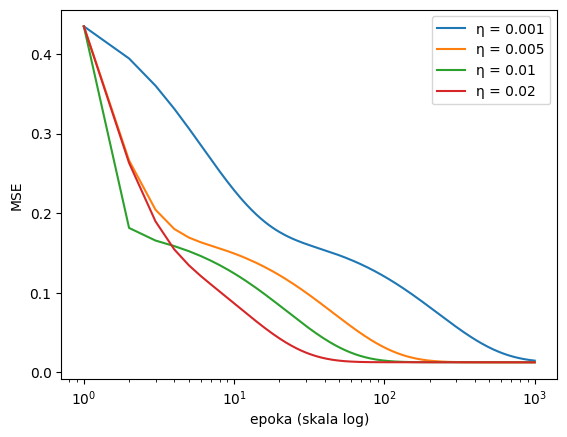

In [13]:
with np.errstate(over="ignore", invalid="ignore"):
    for eta in [0.001, 0.005, 0.01, 0.02]:
        a = AdalineGD(eta=eta, n_iter=1000).fit(X, y)
        plt.plot(range(1, 1001), a.losses_, label=f"η = {eta}")
plt.xscale("log"); plt.xlabel("epoka (skala log)"); plt.ylabel("MSE")
plt.legend(); plt.show()

**Pytanie 6.** Odpowiedz na podstawie tabeli i wykresu:
1. Ile epok potrzebuje $\eta = 0.001$, żeby dojść tam, gdzie $\eta = 0.01$ dochodzi po 100 epokach? Co z tego wynika?
2. Czy strata może spaść do zera? Co się dzieje, gdy dojdzie do „dna”?
3. Czy więcej epok pomaga przy $\eta = 0.025$?
4. Trafność 100% pojawia się dużo wcześniej niż „dno” straty. Co to znaczy?

✍️ **Twoja odpowiedź:**
1. $\eta = 0.001$ potrzebuje ok. 1000 epok, aby dorównać $\eta = 0.01$ po 100 epokach (mniejszy krok wymaga proporcjonalnie więcej epok).
2. Strata nie spada do zera, ponieważ klasy nie są w 100% idealnie liniowo separowalne, a model liniowy ma swoje ograniczenia (osiąga minimalne „dno” ok. $0.012$).
3. Przy $\eta = 0.025$ więcej epok nie pomaga, lecz prowadzi do rozbieżności (przepełnienia numerycznego).
4. Trafność 100% pojawia się wcześniej niż dno straty, ponieważ do poprawnej klasyfikacji wystarczy, aby prosta przeszła między klasami, natomiast Adaline nadal optymalizuje margines i dopasowanie MSE.

## 6. Granica decyzyjna w czasie

Przy $\eta = 0.01$ trafność 100% pojawia się już po kilku epokach. Czy wtedy uczenie się kończy?

Granica decyzyjna Adaline to prosta $z = 0.5$, czyli $w_1 x_1 + w_2 x_2 + b = 0.5$, więc

$$x_2 = \frac{0.5 - b - w_1 x_1}{w_2}.$$

Dla porównania mamy też perceptron z poprzednich zajęć (kod poniżej jest gotowy, uruchom go).

In [14]:
class Perceptron:
    # Perceptron z poprzednich zajęć (etykiety 0/1, granica z = 0)
    def __init__(self, eta=0.1, n_iter=10, random_state=1):
        self.eta, self.n_iter, self.random_state = eta, n_iter, random_state

    def fit(self, X, y):
        rgen = np.random.RandomState(self.random_state)
        self.w_ = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1])
        self.b_ = 0.0
        for _ in range(self.n_iter):
            for xi, target in zip(X, y):
                update = self.eta * (target - self.predict(xi))
                self.w_ += update * xi
                self.b_ += update
        return self

    def predict(self, X):
        return np.where(np.dot(X, self.w_) + self.b_ >= 0.0, 1, 0)

ppn = Perceptron(eta=0.1, n_iter=10).fit(X, y)
print("perceptron: w =", ppn.w_, " b =", ppn.b_, " trafność:", (ppn.predict(X) == y).mean())

perceptron: w = [-0.3538  0.9139]  b = -0.2  trafność: 1.0


### Zadanie 5
Narysuj na jednym wykresie punkty Iris oraz granice decyzyjne Adaline ($\eta = 0.01$) po $1, 5, 20, 100$ i $1000$ epokach. Dla każdej liczby epok wypisz też wagi, bias i trafność. Dorysuj granicę perceptronu (linia przerywana; dla perceptronu granica to $z = 0$, czyli $x_2 = -(b + w_1 x_1)/w_2$).

Epoki:    1 | w = [0.0678 0.0324] | b = 0.0086 | trafność: 95%
Epoki:    5 | w = [0.0658 0.0681] | b = 0.0058 | trafność: 100%
Epoki:   20 | w = [0.0202 0.1545] | b = -0.0098 | trafność: 100%
Epoki:  100 | w = [-0.0754  0.3356] | b = -0.0411 | trafność: 100%
Epoki: 1000 | w = [-0.0994  0.3735] | b = -0.0262 | trafność: 100%


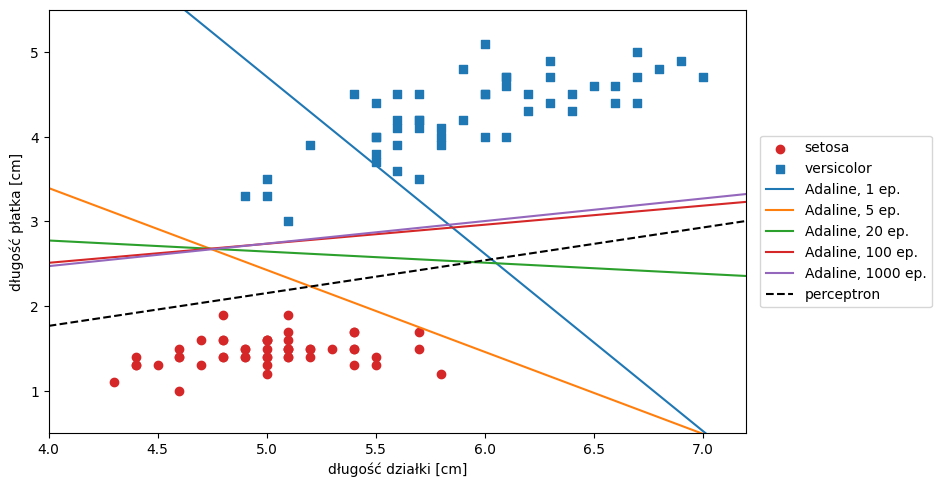

In [15]:
x1 = np.linspace(4.0, 7.2, 2)
plt.figure(figsize=(9, 5.5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:red", marker="o", label="setosa")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:blue", marker="s", label="versicolor")

for n in [1, 5, 20, 100, 1000]:
    ada = AdalineGD(eta=0.01, n_iter=n).fit(X, y)
    w1, w2 = ada.w_
    b = ada.b_
    traf = (ada.predict(X) == y).mean()
    print(f"Epoki: {n:4d} | w = {ada.w_} | b = {b:.4f} | trafność: {traf:.0%}")
    x2 = (0.5 - b - w1 * x1) / w2
    plt.plot(x1, x2, label=f"Adaline, {n} ep.")

ppn = Perceptron(eta=0.1, n_iter=10).fit(X, y)
w1_p, w2_p = ppn.w_
b_p = ppn.b_
x2_p = -(b_p + w1_p * x1) / w2_p
plt.plot(x1, x2_p, "k--", label="perceptron")

plt.xlim(4.0, 7.2); plt.ylim(0.5, 5.5)
plt.xlabel("długość działki [cm]"); plt.ylabel("długość płatka [cm]")
plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5)); plt.show()

**Pytanie 7.** Od której epoki trafność wynosi 100%? Co dzieje się z prostą później i dlaczego? Czym różni się położenie końcowej granicy Adaline od granicy perceptronu i skąd ta różnica?

✍️ **Twoja odpowiedź:** Trafność 100% pojawia się już po ok. 5 epokach, jednak prosta przesuwa się dalej aż do ok. 1000 epok, ponieważ spadek gradientu minimalizuje błąd średniokwadratowy MSE, a nie liczbę błędnych klasyfikacji. Perceptron zatrzymuje się na pierwszej lepszej prostej rozdzielającej, podczas gdy Adaline szuka prostej optymalnej w sensie najmniejszych kwadratów.

## 7. Podsumowanie

Odpowiedz krótko własnymi słowami (kliknij dwukrotnie, żeby edytować):

1. Czym różni się błąd w Adaline od błędu w perceptronie?
 W perceptronie błąd to dyskretna różnica etykiet po funkcji skokowej ($y - \hat{y} \in \{0, \pm 1\}$). W Adaline błąd to ciągła wartość liczbowa przed funkcją skokową ($y - z$).
2. Co to jest funkcja straty i co znaczy „uczenie” w Adaline?
Funkcja straty (MSE) to średni kwadrat błędu dla całego zbioru. Uczenie oznacza minimalizowanie tej straty metodą spadku gradientu.
3. Dlaczego w Adaline $\eta$ ma duże znaczenie, a w perceptronie (przy starcie od zera) nie miało?
W perceptronie $\eta$ skaluje jedynie wielkość poprawki i nie wpływa na ostateczną zbieżność przy danych liniowo separowalnych. W Adaline zbyt duże $\eta$ powoduje natychmiastową rozbieżność algorytmu.
4. Czy za małe $\eta$ można nadrobić liczbą epok? A za duże?
Za małe $\eta$ można nadrobić znacznie większą liczbą epok. Za dużego $\eta$ nie można nadrobić, ponieważ prowadzi do eksplozji numerycznej.
5. Dlaczego granica decyzyjna Adaline przesuwa się dalej, chociaż trafność jest już 100%?
Ponieważ algorytm optymalizuje ciągłą funkcję straty (MSE) całego zbioru, a nie tylko sam fakt poprawnej klasyfikacji poszczególnych punktów.

---
## Zadanie dodatkowe (na ocenę 4/5)

Wróć do dwóch problemów, na których poległ perceptron (bez standaryzacji):

1. **versicolor vs virginica** (kwiaty 50–149, cechy 0 i 2, klasa 1 = virginica). Naucz Adaline dla $\eta \in \{0.001,\ 0.01,\ 0.02\}$ przez 1000 epok. Narysuj straty i regiony decyzyjne dla najlepszego $\eta$, policz trafność. Czy uczenie się stabilizuje? Porównaj z zachowaniem perceptronu. Czy granica stabilności jest taka sama jak dla setosa/versicolor?
2. **XOR** (4 punkty, etykiety $0, 1, 1, 0$). Naucz Adaline ($\eta = 0.1$, 500 epok, `w_init="zeros"`). Wypisz końcowe wagi, bias i $z$ dla czterech punktów. Co „wymyślił” model i dlaczego?

In [16]:
# 1. Versicolor vs Virginica (kwiaty 50–149, cechy 0 i 2)
X_vv = iris.data[50:150][:, [0, 2]]
y_vv = (iris.target[50:150] == 2).astype(int)

for eta in [0.001, 0.01, 0.02]:
    ada_vv = AdalineGD(eta=eta, n_iter=1000).fit(X_vv, y_vv)
    traf_vv = (ada_vv.predict(X_vv) == y_vv).mean()
    print(f"Versicolor vs Virginica | η = {eta} | Trafność: {traf_vv:.0%} | Końcowe MSE: {ada_vv.losses_[-1]:.4f}")

# 2. Problem XOR
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([0, 1, 1, 0])
ada_xor = AdalineGD(eta=0.1, n_iter=500, w_init="zeros").fit(X_xor, y_xor)
print("\nXOR wagi:", ada_xor.w_, "bias:", ada_xor.b_)
print("XOR z:", ada_xor.net_input(X_xor))
print("XOR predykcje:", ada_xor.predict(X_xor))

Versicolor vs Virginica | η = 0.001 | Trafność: 95% | Końcowe MSE: 0.1532
Versicolor vs Virginica | η = 0.01 | Trafność: 93% | Końcowe MSE: 0.0779
Versicolor vs Virginica | η = 0.02 | Trafność: 50% | Końcowe MSE: inf

XOR wagi: [0. 0.] bias: 0.4999999754379278
XOR z: [0.5 0.5 0.5 0.5]
XOR predykcje: [0 0 0 1]


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_784/2252787505.py:40: RuntimeWarning: overflow encountered in square
  loss = (errors ** 2).mean()            # 4. średni błąd kwadratowy (MSE)
